# Time-Series-Based Crop Type Mapping with Sentinel-2 and a Spatio-Temporal U-Net

This notebook maps crop types over farmland in Ontario, Canada from a **time series of Sentinel-2 imagery**. A single image captures a field at only one moment. Crops are easier to tell apart by how their spectral signature changes over the growing season, so the model sees six monthly images (May–October) per year and predicts one crop map per year.

It was produced for the *CS 878 Deep Learning* course project (NUST SEECS, Fall 2023). The brief: learn crop signatures from 2018–2020 and generate a crop-type map for 2021.

| | |
|---|---|
| **Area of interest** | Farmland north of Kitchener–Waterloo/Guelph, Ontario: about 30 km × 22 km (lon −80.687 to −80.314, lat 43.531 to 43.731) |
| **Imagery** | Sentinel-2 L2A, 12 spectral bands at 20 m, one least-cloud mosaic per month (May–Oct), 2018–2021, from the Sentinel Hub Process API |
| **Labels** | Crop-type maps for 2018–2021 supplied with the course project, reclassified into 7 classes |
| **Split** | Train 2018 + 2019, validate 2020, test 2021 |
| **Model** | U-Net whose encoder applies shared 2D convolutions to every month and pools over time, followed by a 2D decoder |
| **Output** | Predicted 2021 crop map, exported as a GeoTIFF and visualised in Google Earth Engine |

**Notebook outline:** Installing Essential Packages → Importing Libraries → Downloading Sentinel-2 Data → Preprocessing (mask alignment, stacking, patching, label encoding) → Training Model → Model Evaluation → Plotting and saving the prediction.

> **Note on running this notebook.** This is the original Google Colab notebook, kept as it was; only these explanatory cells have been added. To run it you need:
> - your own Sentinel Hub credentials;
> - the ground-truth crop maps (`2018.tif` … `2021.tif`), which were uploaded manually to `/content/ground_data/` and aren't included here;
> - `import tensorflow as tf` and `from tensorflow import keras` / `from tensorflow.keras import layers`, which the model cell uses but no cell in this version imports;
> - Google Drive mounted, because the checkpoint and the GeoTIFF are written to `/content/drive/MyDrive/Dl_Assignment/` and there's no mount cell.

Installs the geospatial packages that Colab doesn't include by default:

- **sentinelhub**: Python client for the Sentinel Hub Process API, used to download Sentinel-2 imagery.
- **gdal** and **rasterio**: read, write, reproject and display georeferenced rasters (GeoTIFF).

# ***Installing Essential Packages***

In [ ]:
!pip install sentinelhub
!pip install gdal
!pip install rasterio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.4/245.4 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 9.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.4/49.4 kB 4.3 MB/s eta 0:00:00
  Created wheel for utm: filename=utm-0.7.0-py3-none-any.whl size=6084 sha256=1c52c8a18c241582b7bf196e91b4ea6b9b99986461ede9a98c375e69febbebf4
  Stored in directory: /root/.cache/pip/wheels/2f/a1/c8/543df0e8f5e824c3e92a432e32deb9cd89ae686095ee8cfcbe
Successfully built utm
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.6/20.6 MB 27.0 MB/s eta 0:00:00


# ***Importing Libraries and functions***

Imports the Sentinel Hub request and geometry helpers, the rasterio reprojection utilities used to align the ground-truth masks with the imagery, and the usual numerical and plotting libraries.

In [ ]:

from sentinelhub import (
    CRS,
    BBox,
    DataCollection,
    DownloadRequest,
    MimeType,
    MosaickingOrder,
    SentinelHubDownloadClient,
    SentinelHubRequest,
    bbox_to_dimensions,
    Geometry,
    to_utm_bbox
)

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
#from osgeo import gdal
from rasterio.plot import show
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.warp import calculate_default_transform, reproject, Resampling
from PIL import Image

# ***Downloading Sentinel-2 Data***

### Sentinel Hub configuration

Sets the OAuth client credentials for Sentinel Hub and stores them in an `SHConfig` object, which every download request uses. To run the notebook, replace the values with your own credentials from the Sentinel Hub dashboard.

In [ ]:

CLIENT_ID = 'YOUR_CLIENT_ID'
CLIENT_SECRET = 'YOUR_CLIENT_SECRET'


In [ ]:
from sentinelhub import SHConfig

config = SHConfig()

config.sh_client_id = CLIENT_ID
config.sh_client_secret = CLIENT_SECRET

if not config.sh_client_id or not config.sh_client_secret:
  print('Please provide credentials to use Process API.')

### Area of interest

Defines the bounding box of the study area in WGS 84 coordinates and computes the raster size at 20 m resolution: **1500 × 1124 pixels**, about 30 km × 22 km.

In [ ]:
coords = (-80.68715353939942, 43.5306092687972, -80.31361838314942, 43.73139417849985)

resolution = 20

bbox = BBox(bbox=coords, crs=CRS.WGS84)
image_size = bbox_to_dimensions(bbox, resolution=resolution)

print(f'Image shape at {resolution} m resolution: {image_size}')

Image shape at 20 m resolution: (1500, 1124)


### Download function

`Data_access` sends one Sentinel Hub Process API request for a given date range and saves the response as a GeoTIFF under `/content/data/<year>/<request-hash>/response.tiff`.

- **Collection:** Sentinel-2 **L2A**, i.e. atmospherically corrected surface reflectance.
- **Bands:** all 12 L2A bands, returned in the order B04, B03, B02, B01, B08, B12, B11, B09, B8A, B07, B06, B05 and multiplied by 2.5 (a brightness gain also used in Sentinel Hub visualisation scripts).
- **Mosaicking:** `leastCC`. Scenes in the time window are ordered by tile-level cloud cover, and each pixel takes its value from the least cloudy scene available, giving one composite per window.

The function returns the list of response folders downloaded for that year.

In [ ]:
def Data_access(start_date=None, end_date=None, year=None, mask_crs=None, list1=None):
    evalscript = """//VERSION=3

    function setup() {
      return {
        input: ["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B11","B12"],
        output:{bands: 12}
      };
    }
    function evaluatePixel(sample) {
        return [2.5*sample.B04,2.5*sample.B03,2.5*sample.B02,2.5*sample.B01,2.5*sample.B08,2.5*sample.B12,2.5*sample.B11,2.5*sample.B09,2.5*sample.B8A,2.5*sample.B07,2.5*sample.B06,2.5*sample.B05];
      }


    """

    request = SentinelHubRequest(
        evalscript=evalscript,
        input_data=[
            SentinelHubRequest.input_data(
                data_collection=DataCollection.SENTINEL2_L2A,
                time_interval=(start_date, end_date),

                other_args={"dataFilter": {"mosaickingOrder": "leastCC"}}
            ),
        ],
        responses=[
            SentinelHubRequest.output_response('default', MimeType.TIFF),
        ],
        bbox=bbox,

        geometry = Geometry(geometry={"type":"Polygon","coordinates":[[[-80.68715353939942,43.5306092687972],[-80.31361838314942,43.5306092687972],[-80.31361838314942,43.73139417849985],[-80.68715353939942,43.73139417849985],[-80.68715353939942,43.5306092687972]]]}, crs=CRS.WGS84),

        size=image_size,
        config=config,
        data_folder='/content/data/'+str(year)
    )

    response = request.get_data(save_data=True)
    os.listdir('/content/data/'+str(year))

    # Print the file names

    for file_name in os.listdir('/content/data/'+str(year)):
        if file_name not in list1:
            list1.append(file_name)
    #print(list1)
    return list1

> Note: the next cell deletes `/content/data`, i.e. every downloaded image. It was used to reset the download folder and shouldn't be run after the download step.

In [ ]:
import shutil
shutil.rmtree('/content/data')

## Downloading by defined Time-stamps

Downloads one composite per month from **May to October** for each year from **2018 to 2021**, giving 6 time steps × 4 years = 24 images. The months cover the Ontario growing season, when crops are in the field and spectrally distinguishable; the project brief notes that winter months can be skipped because of snow cover. The next cell lists the response folders downloaded for each year.

In [ ]:
dates = [["-05-01","-05-31"],["-06-01","-06-30"],["-07-01","-07-31"],["-08-01","-08-31"],["-09-01","-09-30"],["-10-01","-10-31"]]
years = [2018, 2019, 2020, 2021]
com_lis = {}
for year in years:
  lis = []
  for date in dates:
    start_date = str(year)+date[0]
    end_date = str(year)+date[1]
    lis = Data_access(start_date=start_date, end_date=end_date, year=year, list1=lis)

  com_lis[year]=lis


In [ ]:
com_lis

{2018: ['12a39abe0eebb9a28294579b7acc9901',
  'f25dfe3267f3a9b005b77b9bcd9d6323',
  '12e1c9f5017a9033ddb8716e95d6e035',
  'fd437c9e1f432f47fe9725e39d043206',
  '77a278b4b8f005e233fc5550c9afc719',
  'd98f402c5e8fbc6369f7e26ce496d63e'],
 2019: ['b49282fbcb91ac9fb3ec61eeac0ed670',
  'c6c858c2c9e8008d8cec763ddaa98c47',
  'e61e2e95cef887a9d60f04071280f2b8',
  'ed70e853d716c0eeab683cbbfb80109c',
  '319b33e21247ff61bfc6b9e80979cf6b',
  'dd3eee2c96249991e6ab981bd302fb23'],
 2020: ['2a101e9949bdf44cdff65ab58f535432',
  '3cdd6171ebf549f9a584b41982d2bdf9',
  '75c084ffd5d755416ad6316afb16a903',
  'bfb2a434f468bd129e8ada9fe60f69cc',
  '49ca9432c18479fd5c11c8b8f44c1de1',
  '53c37e9558f14cfecb250565af4f22f4'],
 2021: ['646b1363378a0f364e8258a03dd166e6',
  '4c90de9861a96cfa81350f73a808312f',
  '8c58e5894feaf2cb3bc156cf401d970d',
  '4eceb98c7266d01e852f092b25aa2103',
  'd3f532c2cdc8bf54657d7ec2adb011b5',
  '6a81cba9493d17eeaa184fa21567e215']}

### Ground-truth crop maps

Creates the folder for the ground-truth crop-type rasters (`2018.tif` … `2021.tif`) supplied with the course project. They were uploaded manually to this folder; the upload isn't part of the notebook. The maps cover 7 classes:

| Code | Class |
|---|---|
| 0 | Others |
| 10 | Land / built-up |
| 50 | Pastures |
| 100 | Wheat |
| 150 | Corn |
| 200 | Soybean |
| 250 | Broadleaf |

In [ ]:
!mkdir /content/ground_data

### Collect image paths per year

Builds one list of response-file paths per year (`path1` = 2018 … `path4` = 2021). Each list holds the six monthly composites in download order (May → October).

In [ ]:
from natsort import natsorted
path1 = []
path2 = []
path3 = []
path4 = []
for a in com_lis.keys():
  if a == 2018:
    for b in com_lis[a]:
      path1.append("/content/data/2018/" + str(b) +"/response.tiff")
  if a == 2019:
    for b in com_lis[a]:
      path2.append("/content/data/2019/" + str(b) +"/response.tiff")
  if a == 2020:
    for b in com_lis[a]:
      path3.append("/content/data/2020/" + str(b) +"/response.tiff")
  if a == 2021:
    for b in com_lis[a]:
      path4.append("/content/data/2021/" + str(b) +"/response.tiff")

### Visual check of the downloaded imagery

Plots the first band (B04, red) of the monthly composites in a 4 × 6 grid. Bright blobs in some months are residual clouds that the least-cloud mosaic couldn't avoid.

> Note: the image index is computed as `4*i + j`, so consecutive rows overlap and the 2021 composites aren't shown. One row per year would need `6*i + j`.

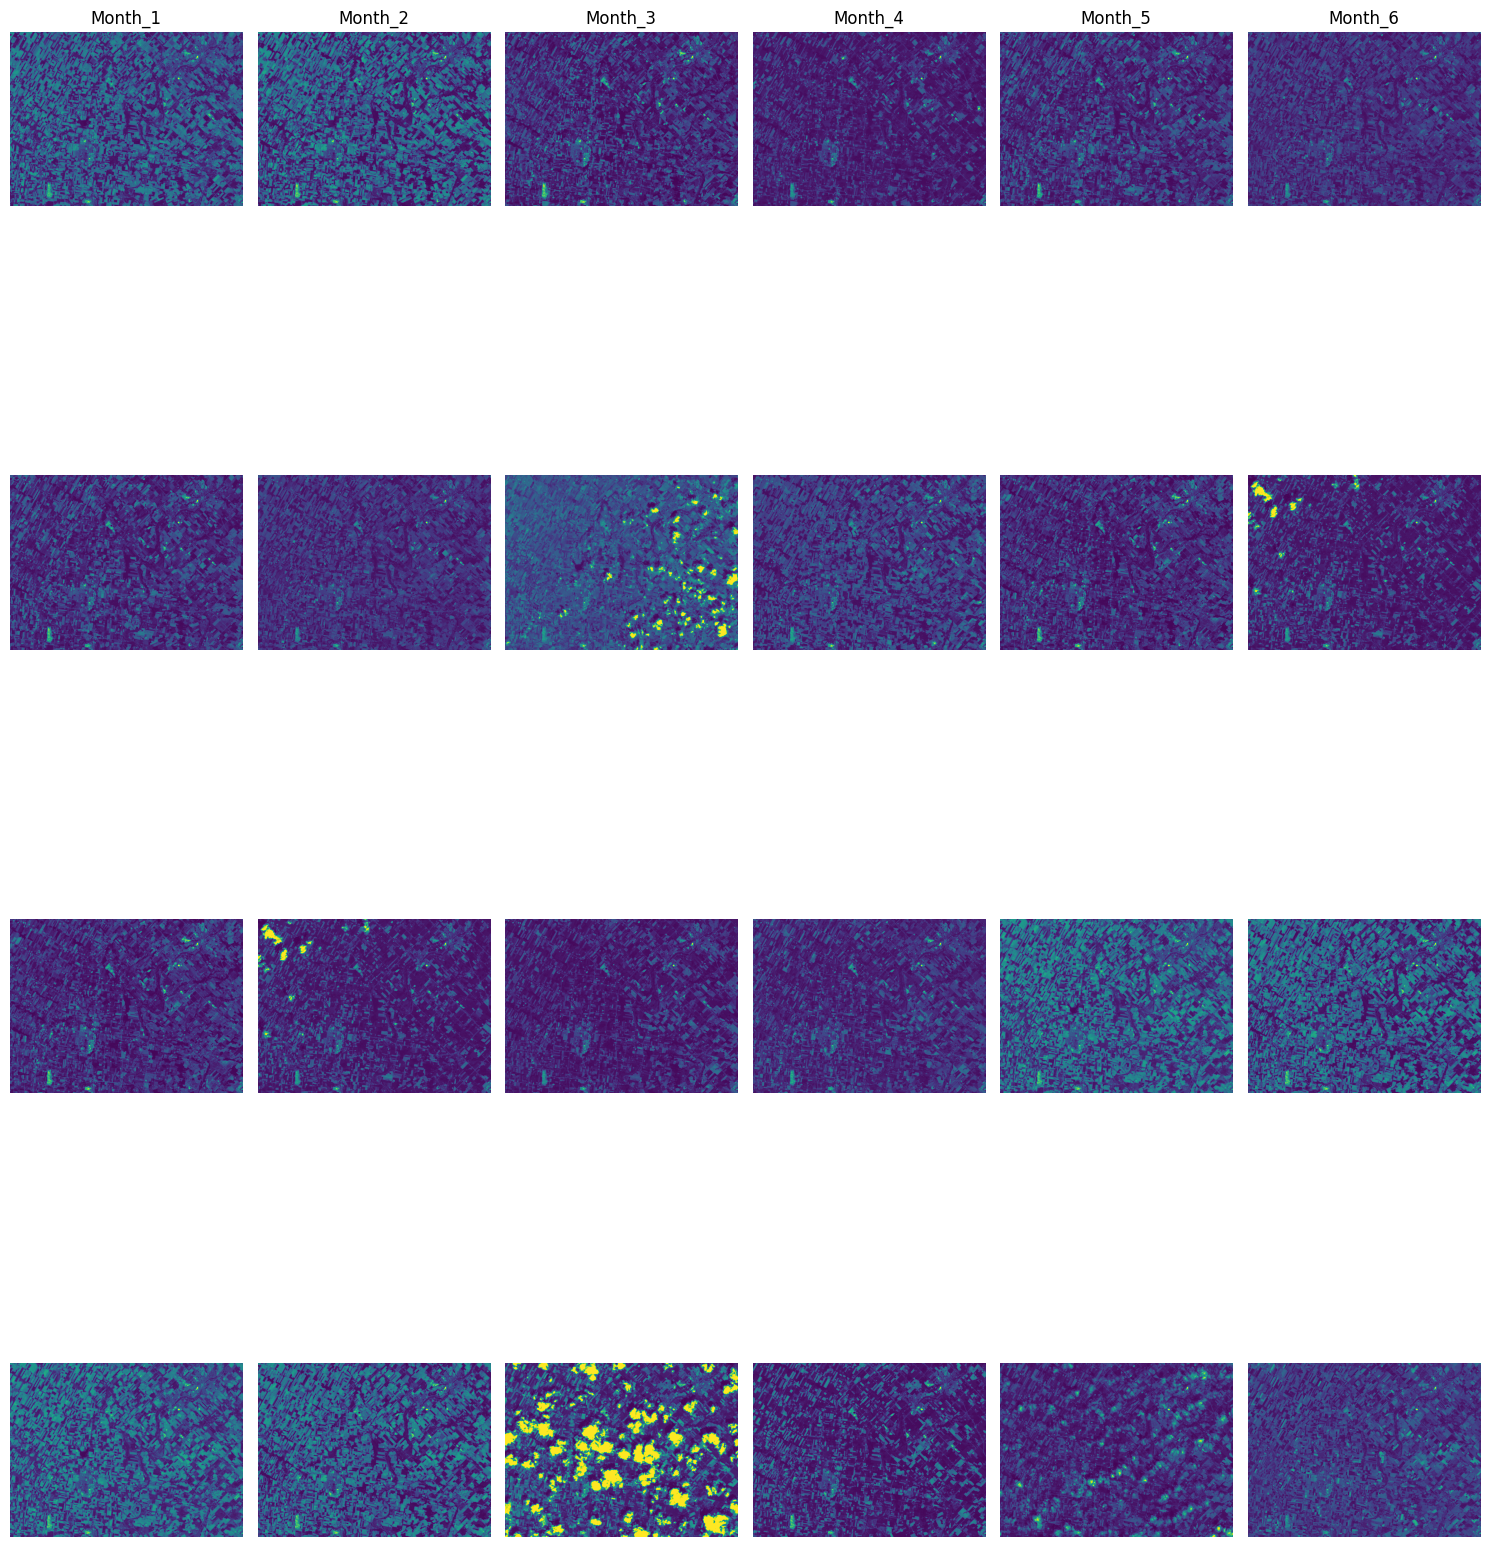

In [ ]:
import matplotlib.pyplot as plt
from tifffile.tifffile import imread

# Combine all paths into one list
all_paths = path1 + path2 + path3 + path4

# Create a figure with 8 rows and 4 columns
fig, axs = plt.subplots(4, 6, figsize=(15, 20))

# Set the titles for the columns
for i in range(6):
    axs[0, i].set_title('Month_' + str(i+1))

# Iterate over each path and each subplot
for i in range(4):
    for j in range(6):
        # Calculate the index of the current path
        index = 4*i + j

        # Load the image from the current path
        img = imread(all_paths[index])

        # Display the image in the current subplot
        axs[i, j].imshow(img[:,:,0])

        # Remove the axis
        axs[i, j].axis('off')

# Display the plot
plt.tight_layout()
plt.show()


Opens the first 2018 composite with rasterio and shows it, then plots each of its 12 bands separately to confirm that all spectral bands downloaded correctly.

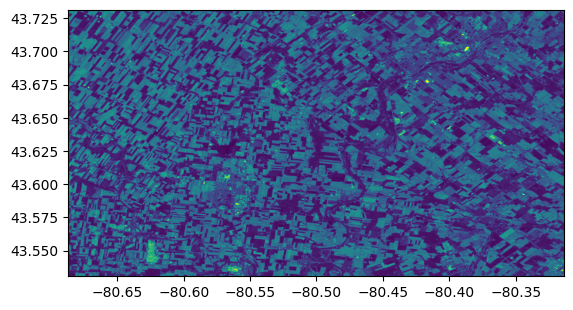

<Axes: >

In [ ]:
img = rasterio.open(path1[0])
show(img)


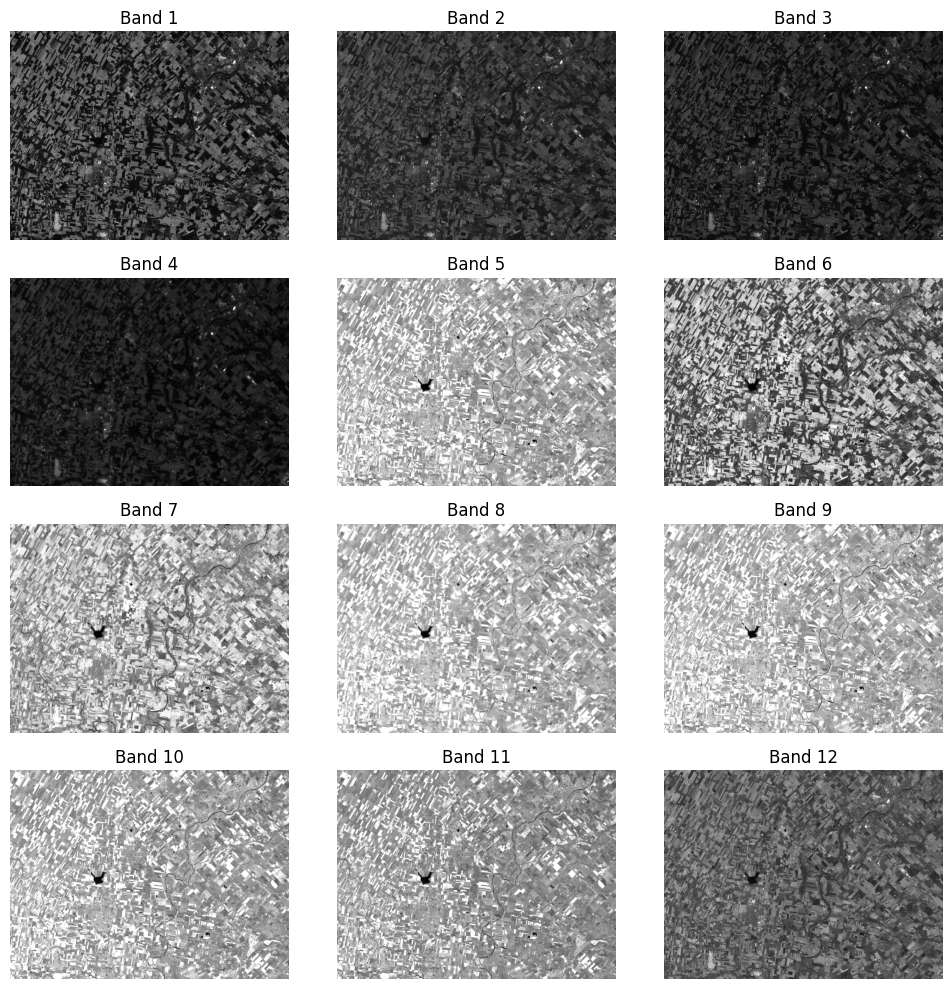

In [ ]:
num_bands = img.count

num_rows = 4
num_cols = 3


fig, axes = plt.subplots(num_rows, num_cols, figsize=(10, 10))

# Loop through each band and plot it in a subplot
for band in range(1, num_bands + 1):

    row_index = (band - 1) // num_cols
    col_index = (band - 1) % num_cols

    band_data = img.read(band)

    # Plot the band in the corresponding subplot
    axes[row_index, col_index].imshow(band_data, cmap='gray')
    axes[row_index, col_index].set_title(f'Band {band}')
    axes[row_index, col_index].axis('off')

plt.tight_layout()
plt.show()

# ***Preprocessing***

## Corping & Aligning Mask using Open-CV & Rasterio

The ground-truth maps come in a different projection, resolution and extent from the Sentinel-2 images: 30 m in an Albers Equal Area projection, versus 20 m in WGS 84. To use them as pixel-wise labels, `align_and_crop`:

1. **Reprojects** the mask into the CRS of the Sentinel-2 image with nearest-neighbour resampling, so class codes are never interpolated.
2. **Crops** the reprojected mask to the bounding box of its labelled (non-zero) pixels.
3. **Saves** it with the Sentinel-2 image's raster profile, so mask and image share the same 1124 × 1500 grid.

> Note: masks and years are paired by the order of `os.listdir('/content/ground_data')`, which isn't guaranteed to be sorted. If the files aren't returned in year order, a mask could be saved under the wrong year.

In [ ]:
# Cv2 resizing and rasterio saving

import cv2
def align_and_crop(image_path, mask_path, cropped_path):

    with rasterio.open(image_path) as src:
        profile = src.profile

    with rasterio.open(mask_path) as src_mask:
        profile_mask = src_mask.profile
        data_mask = src_mask.read()


    transform, width, height = calculate_default_transform(
        src_mask.crs, src.crs, src_mask.width, src_mask.height, *src_mask.bounds
    )

    profile_mask.update({
    'crs': src.crs,
    'transform': transform,
    'width': width,
    'height': height,
    'count': 1
    })

    aligned_mask = np.empty((height, width))

    reproject(
        source=data_mask,
        destination=aligned_mask,
        src_transform=src_mask.transform,
        src_crs=src_mask.crs,
        dst_transform=transform,
        dst_crs=src.crs,
        resampling=Resampling.nearest
    )

    img = aligned_mask.astype(np.uint8)

    y, x = np.where(img != 0)
    bbox = [np.min(x), np.min(y), np.max(x), np.max(y)]

    cropped_img = img[bbox[1]:bbox[3], bbox[0]:bbox[2]]

    #resized_img = cv2.resize(cropped_img, (src.width, src.height), interpolation = cv2.INTER_AREA)

    with rasterio.open(cropped_path, 'w', **profile) as dst:
      dst.write(cropped_img, 1)

image_paths = [path1, path2, path3, path4]
for a, b in enumerate(os.listdir('/content/ground_data')):
  image_path = image_paths[a][0]
  mask_path =   os.path.join('/content/ground_data', b)
  out_dir = "/content/aligned_mask"
  if not os.path.exists(out_dir):
    os.makedirs(out_dir)
  cropped_path = os.path.join(out_dir, 'ground_'+str(years[a])+'.tif')  # Replace with your cropped file path
  align_and_crop(image_path, mask_path, cropped_path)

Compares the aligned 2018 mask (1124 × 1500, same grid as the imagery) with the original ground-truth raster (933 × 1137).

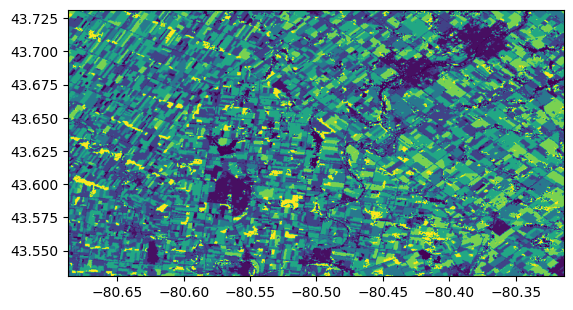

((1124, 1500), (1124, 1500))

In [ ]:
im = rasterio.open('/content/aligned_mask/ground_2018.tif')
show(im)
img.shape, im.shape

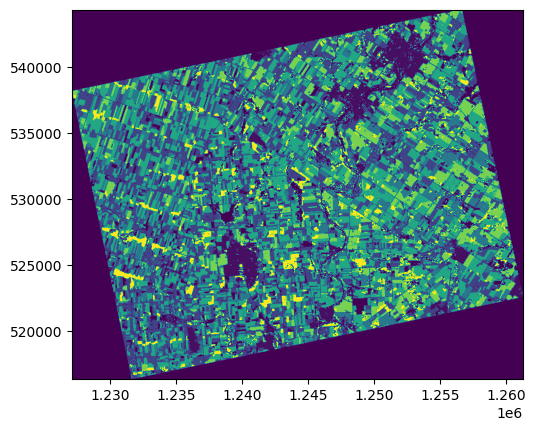

((1124, 1500), (933, 1137))

In [ ]:
# Original Ground
al_c = rasterio.open('/content/ground_data/2018.tif')
show(al_c)
img.shape, al_c.shape

## ***Removing Redundant bands from mask***

Resampling of mask adds extra bands with zero values to mask so we only take first band that has the actuall mask by extracting 1st band from the mask image

The aligned masks were written with the 12-band profile of the Sentinel-2 image, so each file contains 11 empty bands. This cell rewrites every mask as a single-band GeoTIFF.

In [ ]:
for i in os.listdir('/content/aligned_mask'):
  with rasterio.open(os.path.join('/content/aligned_mask', i)) as src:
        profile = src.profile
        img1 = src.read(1)

  out_img = os.path.join('/content/aligned_mask', i)

  # update the metadata
  profile.update({
    'crs': src.crs,
    'count': 1
    })
  # save the band1 as a tif file
  with rasterio.open(out_img, "w", **profile) as dest:
      dest.write(img1, 1) # write band1 to the first band


Confirms that the aligned 2018 mask has the image's spatial size and contains exactly the seven expected class codes.

In [ ]:
am = imread('/content/aligned_mask/ground_2018.tif')
am.shape, np.unique(am)

((1124, 1500), array([  0,  10,  50, 100, 150, 200, 250], dtype=uint8))

## ***Stack Images***

Stacks the six monthly composites of each year into one array per year, saved as `stack_<year>.tiff` with shape **(6, 1124, 1500, 12)** = (months, height, width, bands). Each pixel therefore carries a 6-step time series of 12 spectral bands.

> Note: the stacked reflectance values are used as-is; no further normalisation is applied before training.

In [ ]:
from tifffile.tifffile import imread, imwrite

def stack_tiff_files(input_paths, output_path):
    # Initialize a list to hold the image data
    images = []

    # Loop over the input paths
    for path in input_paths:
        # Read each image and append to the list
        img = imread(path)
        images.append(img)

    # Stack images along a new first axis
    stacked_img = np.stack(images, axis=0)

    # Write the stacked image to the output path
    imwrite(output_path, stacked_img)

if not os.path.exists('/content/stacked'):
  os.makedirs('/content/stacked')
stacks = []
for i, path in enumerate(image_paths):
  out_path = os.path.join('/content/stacked', 'stack_'+str(years[i])+'.tiff')
  stacks.append(out_path)
  print(f"Out_path: {out_path} \nIn path: {path}")
  # Stack TIFF files for each year
  stack_tiff_files(path, out_path)


Out_path: /content/stacked/stack_2018.tiff 
In path: ['/content/data/2018/12a39abe0eebb9a28294579b7acc9901/response.tiff', '/content/data/2018/f25dfe3267f3a9b005b77b9bcd9d6323/response.tiff', '/content/data/2018/12e1c9f5017a9033ddb8716e95d6e035/response.tiff', '/content/data/2018/fd437c9e1f432f47fe9725e39d043206/response.tiff', '/content/data/2018/77a278b4b8f005e233fc5550c9afc719/response.tiff', '/content/data/2018/d98f402c5e8fbc6369f7e26ce496d63e/response.tiff']
Out_path: /content/stacked/stack_2019.tiff 
In path: ['/content/data/2019/b49282fbcb91ac9fb3ec61eeac0ed670/response.tiff', '/content/data/2019/c6c858c2c9e8008d8cec763ddaa98c47/response.tiff', '/content/data/2019/e61e2e95cef887a9d60f04071280f2b8/response.tiff', '/content/data/2019/ed70e853d716c0eeab683cbbfb80109c/response.tiff', '/content/data/2019/319b33e21247ff61bfc6b9e80979cf6b/response.tiff', '/content/data/2019/dd3eee2c96249991e6ab981bd302fb23/response.tiff']
Out_path: /content/stacked/stack_2020.tiff 
In path: ['/content/

In [ ]:
stacks

['/content/stacked/stack_2018.tiff',
 '/content/stacked/stack_2019.tiff',
 '/content/stacked/stack_2020.tiff',
 '/content/stacked/stack_2021.tiff']

import shutil
shutil.rmtree('/content/stacked')

A quick check of one stacked year (2020): display one band of the second month and confirm the stack shape.

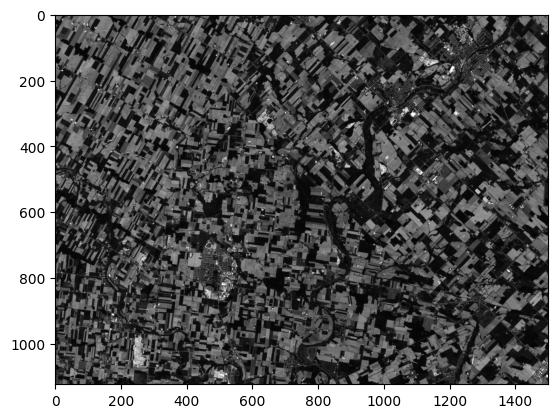

In [ ]:

sta =imread('/content/stacked/stack_2020.tiff')

plt.imshow(sta[1,:,:,0], cmap='gray')

In [ ]:
sta.shape

(6, 1124, 1500, 12)

## ***Creating Patches***

Installs and imports `patchify`, which splits the large rasters into fixed-size tiles.

In [ ]:
!pip install patchify

In [ ]:
from patchify import patchify, unpatchify
from scipy import stats
from tifffile.tifffile import imread
from skimage.util import view_as_windows

### Patch extraction

The full scene is too large to feed to the network in one piece, so it is cut into non-overlapping **64 × 64** tiles:

- `create_patches` tiles each month of a 4D image stack separately, or tiles a 2D mask directly.
- `process_images` loads an image stack and its mask and returns matching image and mask patches.

A 1124 × 1500 scene yields 17 × 23 = **391 patches**. The last 36 rows and 28 columns, which don't fill a whole patch, are dropped.

In [ ]:

def create_patches(image, patch_size):
    patches_list = []

    # Check if the input image has a time-stamp dimension
    if len(image.shape) == 4:
        # For images with a time-stamp dimension
        for t in range(image.shape[0]):
            patches = patchify(image[t], (patch_size, patch_size, image.shape[3]), step=patch_size)
            single_time_patches = []
            for i in range(patches.shape[0]):
                for j in range(patches.shape[1]):
                    single_patch_img = patches[i, j, 0, :]  # Extract the patch without the singleton dimensions
                    single_time_patches.append(single_patch_img)

            single_time = np.array(single_time_patches)
            patches_list.append(single_time)

        patches_data = np.array(patches_list)
    else:
       patches = patchify(image, (patch_size, patch_size), step=patch_size)
       for i in range(patches.shape[0]):
            for j in range(patches.shape[1]):
                single_patch_img = patches[i,j,:,:]
                #single_patch_img = single_patch_img[0]
                patches_list.append(single_patch_img)
                patches_data = np.array(patches_list)

    return patches_data

def process_images(training_image_path, ground_truth_path, patch_size):
    # Loading Images
    training_image = imread(training_image_path)
    ground_truth = imread(ground_truth_path)  # Keep only one channel from ground truth

    print(f"Train Shape: {training_image.shape} \nMask shape: {ground_truth.shape}")

    # Creating Patches
    training_patches = create_patches(training_image, patch_size)
    ground_truth_patches = create_patches(ground_truth, patch_size)
    print(f"Ground patches shape: {ground_truth_patches.shape} \nTraining patches shape: {training_patches.shape}")

    return training_patches, ground_truth_patches

### Train / validation / test split by year

The split is **temporal**: the model is evaluated on a year it never saw during training.

| Split | Year(s) | Image patches | Mask patches |
|---|---|---|---|
| Train | 2018, 2019 | (782, 6, 64, 64, 12) | (782, 64, 64) |
| Validation | 2020 | (391, 6, 64, 64, 12) | (391, 64, 64) |
| Test | 2021 | (391, 6, 64, 64, 12) | (391, 64, 64) |

The patch arrays are transposed so the patch index comes first and each sample is a (time, height, width, bands) cube.

In [ ]:

# Training Patches
training_data = []
mask_data = []

# Defining Image paths
paths = [('/content/stacked/stack_2018.tiff', '/content/aligned_mask/ground_2018.tif'),
         ('/content/stacked/stack_2019.tiff', '/content/aligned_mask/ground_2019.tif')]

# Defining patch size
patch_size = 64

for path in paths:
    # Training image path is at index 0 and corresponding ground truth is at index 1
    training_image_path = path[0]
    ground_truth_path = path[1]

    # Calling Function to return patches and labels for patches of the whole training data
    training_patches, mask_patches = process_images(training_image_path, ground_truth_path, patch_size)

    # Append the patches to the data lists
    training_data.append(training_patches)
    mask_data.append(mask_patches)

# Combine Patches for 2018 and 2019 into single array
training_data = np.transpose(np.concatenate(training_data, axis=1), (1, 0, 2, 3, 4))
train_mask = np.concatenate(mask_data, axis=0)

## Valid Patches
valid_path = '/content/stacked/stack_2020.tiff'
valid_mask_path = '/content/aligned_mask/ground_2020.tif'

valid_patches, valid_mask = process_images(valid_path, valid_mask_path, patch_size)
valid_data = np.transpose(np.array(valid_patches), (1, 0, 2, 3, 4))
valid_mask = np.array(valid_mask)

# Test Patches
test_path = '/content/stacked/stack_2021.tiff'
test_mask_path = '/content/aligned_mask/ground_2021.tif'

test_patches, test_mask = process_images(test_path, test_mask_path, patch_size)
test_data = np.transpose(np.array(test_patches), (1, 0, 2, 3, 4))
test_mask = np.array(test_mask)


print(f"\n\nTrain data Shape: {training_data.shape} \nTrain Mask shape: {train_mask.shape}")
print(f"Valid data Shape: {valid_data.shape} \nValid Mask shape: {valid_mask.shape}")
print(f"test data Shape: {test_data.shape} \ntest Mask shape: {test_mask.shape}")


Train Shape: (6, 1124, 1500, 12) 
Mask shape: (1124, 1500)
Ground patches shape: (391, 64, 64) 
Training patches shape: (6, 391, 64, 64, 12)
Train Shape: (6, 1124, 1500, 12) 
Mask shape: (1124, 1500)
Ground patches shape: (391, 64, 64) 
Training patches shape: (6, 391, 64, 64, 12)
Train Shape: (6, 1124, 1500, 12) 
Mask shape: (1124, 1500)
Ground patches shape: (391, 64, 64) 
Training patches shape: (6, 391, 64, 64, 12)
Train Shape: (6, 1124, 1500, 12) 
Mask shape: (1124, 1500)
Ground patches shape: (391, 64, 64) 
Training patches shape: (6, 391, 64, 64, 12)


Train data Shape: (782, 6, 64, 64, 12) 
Train Mask shape: (782, 64, 64)
Valid data Shape: (391, 6, 64, 64, 12) 
Valid Mask shape: (391, 64, 64)
test data Shape: (391, 6, 64, 64, 12) 
test Mask shape: (391, 64, 64)


Displays one training patch (one band of one month) next to its label mask.

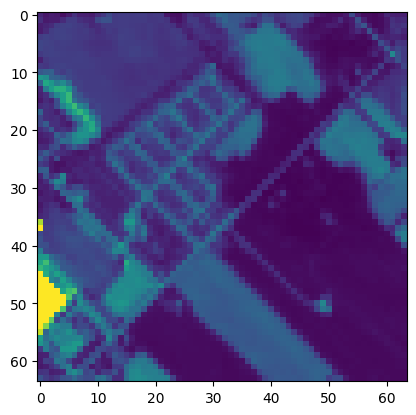

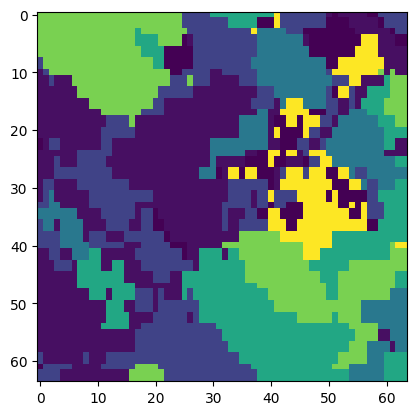

In [ ]:
plt.figure(1)
plt.imshow(training_data[500, 1, :,:, 0])
plt.figure(2)
plt.imshow(train_mask[500, :,:])

### **Encoding Labels in Mask**

The masks hold the raw class codes {0, 10, 50, 100, 150, 200, 250}. They're remapped to consecutive indices 0–6, as categorical cross-entropy and one-hot encoding require.

In [ ]:
np.unique(test_mask), np.unique(train_mask), np.unique(valid_mask)

(array([  0,  10,  50, 100, 150, 200, 250], dtype=uint8),
 array([  0,  10,  50, 100, 150, 200, 250], dtype=uint8),
 array([  0,  10,  50, 100, 150, 200, 250], dtype=uint8))

In [ ]:
class_mapping = {0: 0, 10: 1, 50: 2, 100: 3, 150: 4, 200: 5, 250: 6}

# Apply the mapping to convert pixel values to class labels
train_mask = np.vectorize(class_mapping.get)(train_mask)
valid_mask = np.vectorize(class_mapping.get)(valid_mask)
test_mask = np.vectorize(class_mapping.get)(test_mask)
np.unique(test_mask), np.unique(train_mask), np.unique(valid_mask)

(array([0, 1, 2, 3, 4, 5, 6]),
 array([0, 1, 2, 3, 4, 5, 6]),
 array([0, 1, 2, 3, 4, 5, 6]))

# ***Training Model***

Shape checks before building the model: 782 training samples, each a 6 × 64 × 64 × 12 time-series cube with a 64 × 64 label mask.

In [ ]:

# Assuming train_mask is the original target data
expanded_train_mask = np.expand_dims(train_mask, axis=1)  # Adds a new dimension for samples

# Verify the shape of the expanded target data
print(expanded_train_mask.shape)

(782, 1, 64, 64)


In [ ]:
training_data.shape, train_mask.shape

((782, 6, 64, 64, 12), (782, 64, 64))

## ***3D-to-2D UNET***

### ***Working Architecture***

### Model architecture

A U-Net adapted to time-series input: it takes a stack of six monthly images and outputs a single 2D crop map.

- **Temporal encoder:** three resolution levels with 32, 64 and 128 filters, followed by a 256-filter bottleneck. Each level applies two 3 × 3 convolutions to every month independently through `TimeDistributed`, so the weights are shared across months, then downsamples ×2 with max pooling.
- **Collapsing time:** the skip connections and the bottleneck are reduced from 6 time steps to 1 with `MaxPooling3D((6, 1, 1))`, which keeps each feature's strongest response over the season. A reshape then drops the time axis.
- **Spatial decoder:** a standard 2D U-Net decoder. Three transposed-convolution upsampling steps, each concatenated with the time-pooled skip connection from the matching encoder level and followed by two 3 × 3 convolutions.
- **Output:** a 1 × 1 convolution with softmax over the **7 classes**, giving a 64 × 64 × 7 probability map per patch.

Input shape (6, 64, 64, 12); 2,294,183 trainable parameters. A fourth encoder/decoder level (512/1024 filters) is present but commented out.

> Note: this cell uses `tf`, `keras` and `layers`, which aren't imported anywhere in this version of the notebook (see the note at the top).

In [ ]:

def unet_model(input_shape, num_classes):
    # Encoder
    inputs = keras.Input(shape=input_shape)
    x = layers.TimeDistributed(layers.Conv2D(32, 3, padding="same", activation="relu"))(inputs)
    x = layers.TimeDistributed(layers.Conv2D(32, 3, padding="same", activation="relu"))(x)

    skip1 = layers.MaxPooling3D((6, 1, 1))(x)

    x = layers.TimeDistributed(layers.MaxPooling2D(2))(x)
    x = layers.TimeDistributed(layers.Conv2D(64, 3, padding="same", activation="relu"))(x)
    x = layers.TimeDistributed(layers.Conv2D(64, 3, padding="same", activation="relu"))(x)

    skip2 = layers.MaxPooling3D((6, 1, 1))(x)

    x = layers.TimeDistributed(layers.MaxPooling2D(2))(x)
    x = layers.TimeDistributed(layers.Conv2D(128, 3, padding="same", activation="relu"))(x)
    x = layers.TimeDistributed(layers.Conv2D(128, 3, padding="same", activation="relu"))(x)

    skip3 = layers.MaxPooling3D((6, 1, 1))(x)

    x = layers.TimeDistributed(layers.MaxPooling2D(2))(x)
    x = layers.TimeDistributed(layers.Conv2D(256, 3, padding="same", activation="relu"))(x)
    x = layers.TimeDistributed(layers.Conv2D(256, 3, padding="same", activation="relu"))(x)
    """
    skip4 = layers.MaxPooling3D((6, 1, 1))(x)
    x = layers.TimeDistributed(layers.MaxPooling2D(2))(x)
    x = layers.TimeDistributed(layers.Conv2D(1024, 3, padding="same", activation="relu"))(x)
    x = layers.TimeDistributed(layers.Conv2D(1024, 3, padding="same", activation="relu"))(x)
    """
    # Add a MaxPooling3D layer without TimeDistributed wrapper
    x = layers.MaxPooling3D((6, 1, 1))(x)
    # Use tf.reshape to get rid of the time-stamp dimension
    x = tf.reshape(x, (-1, x.shape[2], x.shape[3], x.shape[4]))

    # Decoder
    """
    x = layers.Conv2DTranspose(512, 2, strides=2, padding="same", activation="relu")(x)
    x = layers.Concatenate()([x, tf.reshape(skip4, (-1, skip4.shape[2], skip4.shape[3], skip4.shape[4]))])
    x = layers.Conv2D(512, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(512, 3, padding="same", activation="relu")(x)
    """
    x = layers.Conv2DTranspose(256, 2, strides=2, padding="same", activation="relu")(x)
    x = layers.Concatenate()([x, tf.reshape(skip3, (-1, skip3.shape[2], skip3.shape[3], skip3.shape[4]))])
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)

    x = layers.Conv2DTranspose(128, 2, strides=2, padding="same", activation="relu")(x)
    x = layers.Concatenate()([x, tf.reshape(skip2, (-1, skip2.shape[2], skip2.shape[3], skip2.shape[4]))])
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)

    x = layers.Conv2DTranspose(64, 2, strides=2, padding="same", activation="relu")(x)
    x = layers.Concatenate()([x, tf.reshape(skip1, (-1, skip1.shape[2], skip1.shape[3], skip1.shape[4]))])
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)

    # Output layer
    outputs = layers.Conv2D(num_classes, 1, padding="same", activation="softmax")(x)

    # Create and return the model
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

# Define input shape and number of classes
input_shape = (6, 64, 64, 12)
num_classes = 7  # Assuming you want a binary mask

# Create the model
model = unet_model(input_shape, num_classes)

# Print the model summary
model.summary()


Model: "model_7"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_8 (InputLayer)        [(None, 6, 64, 64, 12)]      0         []                            
                                                                                                  
 time_distributed_95 (TimeD  (None, 6, 64, 64, 32)        3488      ['input_8[0][0]']             
 istributed)                                                                                      
                                                                                                  
 time_distributed_96 (TimeD  (None, 6, 64, 64, 32)        9248      ['time_distributed_95[0][0]'] 
 istributed)                                                                                      
                                                                                            

## **One-Hot Encoding**

Converts the integer label masks into one-hot tensors (64 × 64 × 7) to match the softmax output and categorical cross-entropy loss.

In [ ]:
from tensorflow.keras.utils import to_categorical
categorical_train_mask = to_categorical(train_mask, num_classes=num_classes)
categorical_valid_mask = to_categorical(valid_mask, num_classes=num_classes)
categorical_test_mask = to_categorical(test_mask, num_classes=num_classes)



## Traning

### Training

- **Loss / optimiser:** categorical cross-entropy with Adam at Keras' default learning rate.
- **Schedule:** 10 epochs, batch size 2, validated on the 2020 patches.
- **Checkpointing:** `ModelCheckpoint` saves the weights with the best validation accuracy to Google Drive (`unet_project.h5`).

**Recorded run:** training accuracy rises from 0.328 to 0.490 over 10 epochs and training loss falls from 1.954 to 1.289. Validation accuracy peaks at **0.490 (epoch 5)** and ends at 0.457.

> Note on the IoU metric: `MeanIoU` expects integer class labels, but here it receives one-hot targets and softmax probabilities. It therefore stays at a constant **0.4286 (= 3/7)** throughout training and testing, and doesn't measure the real per-class IoU.

In [ ]:
from tensorflow.keras.metrics import MeanIoU
iou_metric = MeanIoU(num_classes=num_classes)
from tensorflow.keras.callbacks import ModelCheckpoint

# Define the ModelCheckpoint callback
checkpoint_filepath = '/content/drive/MyDrive/Dl_Assignment/unet_project.h5'
model_checkpoint = ModelCheckpoint(filepath=checkpoint_filepath, save_best_only=True, monitor='val_accuracy', mode='max', verbose=1)

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy', iou_metric])


r = model.fit(training_data, categorical_train_mask, epochs=10, batch_size=2, validation_data=[valid_data, categorical_valid_mask], callbacks=[model_checkpoint])

Epoch 1/10
389/391 [============================>.] - ETA: 0s - loss: 1.9557 - accuracy: 0.3284 - mean_io_u_2: 0.4286
Epoch 1: val_accuracy improved from -inf to 0.36048, saving model to /content/drive/MyDrive/Dl_Assignment/unet_project.h5


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


391/391 [==============================] - 14s 22ms/step - loss: 1.9538 - accuracy: 0.3282 - mean_io_u_2: 0.4286 - val_loss: 1.6596 - val_accuracy: 0.3605 - val_mean_io_u_2: 0.4286
Epoch 2/10
391/391 [==============================] - ETA: 0s - loss: 1.4960 - accuracy: 0.4011 - mean_io_u_2: 0.4286
Epoch 2: val_accuracy improved from 0.36048 to 0.45789, saving model to /content/drive/MyDrive/Dl_Assignment/unet_project.h5
391/391 [==============================] - 6s 16ms/step - loss: 1.4960 - accuracy: 0.4011 - mean_io_u_2: 0.4286 - val_loss: 1.4852 - val_accuracy: 0.4579 - val_mean_io_u_2: 0.4286
Epoch 3/10
390/391 [============================>.] - ETA: 0s - loss: 1.4397 - accuracy: 0.4253 - mean_io_u_2: 0.4286
Epoch 3: val_accuracy improved from 0.45789 to 0.47620, saving model to /content/drive/MyDrive/Dl_Assignment/unet_project.h5
391/391 [==============================] - 8s 21ms/step - loss: 1.4394 - accuracy: 0.4254 - mean_io_u_2: 0.4286 - val_loss: 1.4761 - val_accuracy: 0.4762

# ***Model Evaluation***

Evaluates the model on the held-out **2021** patches.

**Recorded result:** test loss 1.454, pixel accuracy **0.409**. The reported mean IoU of 0.4286 is the degenerate value described above. `evaluate` uses the in-memory weights from the final epoch, not the best checkpoint saved during training.

In [ ]:
model.evaluate(test_data,categorical_test_mask)

13/13 [==============================] - 1s 43ms/step - loss: 1.4539 - accuracy: 0.4089 - mean_io_u_2: 0.4286


[1.4538534879684448, 0.4089280664920807, 0.4285714328289032]

### Predict the 2021 crop map

Runs the model on all 391 test patches and takes the arg-max over the class dimension, giving a (391, 64, 64) array of class indices.

In [ ]:
pred = model.predict(test_data)

13/13 [==============================] - 1s 40ms/step


In [ ]:
pred1 = np.argmax(pred, 3)

In [ ]:
pred1.shape

(391, 64, 64)

Maps the predicted class indices back to the original class codes (0, 10, 50, 100, 150, 200, 250), so the prediction can be compared with, and exported in the same format as, the ground-truth rasters.

In [ ]:
class_mapping2 = {0: 0, 1: 10, 2: 50, 3: 100, 4: 150, 5: 200, 6: 250}


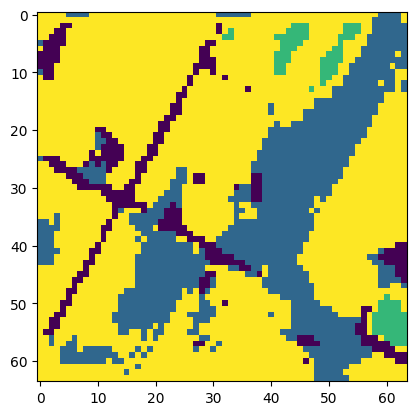

In [ ]:
plt.imshow(pred1[1])

In [ ]:
pred1[1]

array([[4, 4, 4, ..., 2, 2, 4],
       [4, 4, 4, ..., 2, 2, 4],
       [4, 4, 4, ..., 2, 2, 2],
       ...,
       [4, 4, 4, ..., 4, 4, 4],
       [4, 4, 4, ..., 4, 4, 4],
       [4, 4, 4, ..., 4, 4, 4]])

In [ ]:
test_results = np.vectorize(class_mapping2.get)(pred1)

### Re-assemble the full scene

Places the 391 predicted patches back into their grid positions (17 rows × 23 columns) on a 1124 × 1500 canvas.

> Note: the strip along the bottom and right edges that the patches don't cover (36 rows and 28 columns) is filled with the mean of all predicted class codes (≈ 96). That isn't a valid class, so these border pixels should be ignored when interpreting the map.

In [ ]:
from patchify import unpatchify

In [ ]:
#test_mask_path = '/content/aligned_mask/ground_2021.tif'
test_img = imread(test_mask_path)

In [ ]:
test_img.shape

(1124, 1500)

In [ ]:
filled_img = np.zeros(test_img.shape)
rows = 1124 // 64
cols = 1500 // 64

# Iterate over the patches and add them to the correct position in test_img
for i in range(rows):
    for j in range(cols):
        filled_img[i*64:(i+1)*64, j*64:(j+1)*64] = test_results[i*cols + j]

# If there are any remaining pixels in test_img, fill them with a suitable value (e.g., the average of all patches)
if rows * 64 < 1124 or cols * 64 < 1500:
    filled_img[rows*64:, :] = np.mean(test_results)
    filled_img[:, cols*64:] = np.mean(test_results)

print(filled_img.shape)

(1124, 1500)


## **Plotting Prediction**

Predicted 2021 crop map (first plot) next to the 2021 ground truth (second plot). The prediction recovers the main field structure and the large homogeneous areas, but it favours a few dominant classes. In the exported GeoTIFF, corn (150) and pastures (50) make up about 70 % of all pixels, while soybean (200) is almost never predicted.

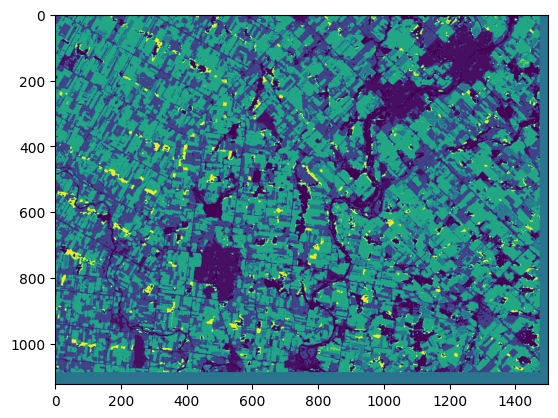

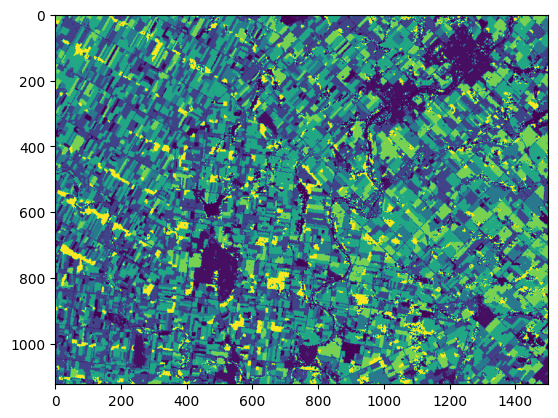

In [ ]:
plt.figure(1)
plt.imshow(filled_img)

ground = imread('/content/aligned_mask/ground_2021.tif')
plt.figure(2)
plt.imshow(ground)

## **Saving Predicted Mask as Geotiff**

Exports the predicted map as a GeoTIFF (`2021_pred_proj.tif`) so it can be loaded into GIS tools and Google Earth Engine. The raster profile (CRS, transform, size) is copied from the original 2021 ground-truth file.

> Note: the prediction is on the 1124 × 1500 Sentinel-2 grid (WGS 84), but the profile copied here describes the 933 × 1137, 30 m Albers grid of the original ground truth. GDAL resamples the array to fit on write, without reprojecting it, so the georeferencing of the exported map is only approximate.

In [ ]:
from rasterio.transform import from_origin
with rasterio.open('/content/ground_data/2021.tif') as src:
    transform = src.transform
    crs = src.crs
    profile = src.profile

# Create a new GeoTIFF file with the filled image and georeferencing information
output_path = '/content/drive/MyDrive/Dl_Assignment/2021_pred_proj.tif'
with rasterio.open(output_path, 'w', **profile) as dst:
    dst.write(filled_img, 1)

Re-opens the exported GeoTIFF to confirm that it was written correctly and carries map coordinates.

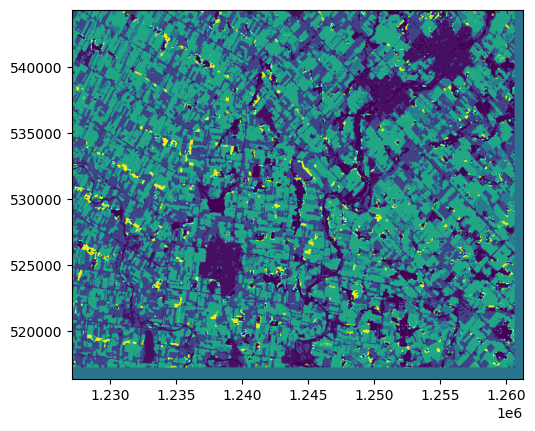

<Axes: >

In [ ]:
pred_mask = rasterio.open(output_path)
show(pred_mask)

## Summary

- **Data pipeline:** Sentinel-2 L2A imagery (12 bands, 20 m) was downloaded as monthly least-cloud composites for May–October 2018–2021. The supplied crop maps were reprojected onto the image grid, and both were cut into 64 × 64 patches that each hold a 6-month time series.
- **Model:** a spatio-temporal U-Net. Shared 2D convolutions are applied per month, temporal max-pooling collapses the season into one feature map, and a 2D decoder predicts 7 crop/land-cover classes.
- **Results (recorded outputs):**

| | Accuracy | Loss |
|---|---|---|
| Train (2018–2019), epoch 10 | 0.490 | 1.289 |
| Validation (2020), best epoch (5) | 0.490 | 1.422 |
| Test (2021), final-epoch weights | 0.409 | 1.454 |

  The `MeanIoU` value logged by Keras (0.4286) is an artefact of passing one-hot targets to the metric. It isn't a valid IoU.
- **Visualisation:** the predicted 2021 map was exported as a GeoTIFF and loaded into Google Earth Engine; a screenshot is in the repository's `assets/` folder.
- **Possible improvements:** normalise the input bands; use a class-aware IoU metric (e.g. `OneHotMeanIoU`) and per-class scores; train longer with learning-rate tuning; include 2020 in training; predict with overlapping tiles to cover the scene borders; reproject the prediction properly before export.